# Data Exploration and Preprocessing — Bayyinah Burnout Models

This notebook explores the dataset and builds the preprocessing used by both burnout models (regression and classification).

**Dataset:** [Mental Health & Burnout in Tech Workers 2026](https://www.kaggle.com/datasets/mohankrishnathalla/mental-health-and-burnout-in-tech-workers-2026)

The functions defined here are also saved in `preprocessing.py`, which the model notebooks and the Bayyinah backend import, so every part of the project uses exactly the same steps.

**Contents**
1. Data overview
2. Data quality checks
3. Exploratory data analysis
4. Preprocessing
    - 4.1 Dropping leakage columns
    - 4.2 Outliers
    - 4.3 Logic rules
    - 4.4 Train/test split
    - 4.5 Preprocessing pipeline

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

plt.rcParams["figure.dpi"] = 110

In [2]:
DATA_PATH = "mental_health_burnout_tech_2026.csv"
TARGET = "burnout_score"
SEED = 42

# burnout_level is just the target split into groups -> leakage.
# phq9/gad7 are depression/anxiety scores measured at the same time as burnout,
# and the last two columns are results of burnout, not causes.
DROP_COLS = [
    "employee_id", "burnout_level",
    "phq9_score", "phq9_category", "gad7_score", "gad7_category",
    "seeks_mental_health_support", "job_change_intention",
]

GENDER_RECODE = {"Non-binary": "Prefer not to say"}

## 1. Data overview

In [3]:
def load_data(path=DATA_PATH):
    df = pd.read_csv(path)
    df["gender"] = df["gender"].replace(GENDER_RECODE)
    return df

In [4]:
df = load_data()
print(df.shape)
df.head()

(100000, 36)


,employee_id,age,gender,country,job_role,seniority_level,years_experience,years_at_company,company_size,industry,...,autonomy_score,stress_score,burnout_score,phq9_score,phq9_category,gad7_score,gad7_category,burnout_level,seeks_mental_health_support,job_change_intention
0,1,33,Male,India,Software Engineer,Lead,11,6.4,Small (51-200),Healthcare Tech,...,6.1,10.0,10.0,19,Moderately Severe (15-19),12,Moderate (10-14),Severe,1,1
1,2,24,Prefer not to say,USA,Full Stack Developer,Manager,0,5.7,Startup (1-50),Fintech,...,5.4,9.3,7.0,8,Mild (5-9),6,Mild (5-9),High,1,1
2,3,36,Prefer not to say,USA,Software Engineer,Lead,14,5.6,Mid (201-1000),Fintech,...,4.1,8.9,8.5,8,Mild (5-9),9,Mild (5-9),Severe,0,1
3,4,38,Prefer not to say,USA,Software Engineer,Lead,14,1.2,Mid (201-1000),SaaS / Cloud,...,7.3,10.0,10.0,14,Moderate (10-14),11,Moderate (10-14),Severe,0,1
4,5,22,Prefer not to say,France,ML Engineer,Junior,0,3.0,Small (51-200),AI / ML Startup,...,4.4,7.7,5.4,8,Mild (5-9),0,Minimal (0-4),Moderate,1,0


In [5]:
df.dtypes.value_counts()

int64      15
float64    11
str        10
Name: count, dtype: int64

In [6]:
for c in df.select_dtypes(exclude="number").columns:
    print(f"{c} ({df[c].nunique()}): {df[c].value_counts().to_dict()}\n")

gender (3): {'Male': 65243, 'Female': 29759, 'Prefer not to say': 4998}

country (10): {'USA': 31966, 'India': 21998, 'UK': 9939, 'Canada': 7940, 'Germany': 7099, 'Australia': 6169, 'Brazil': 4050, 'Netherlands': 3956, 'Singapore': 3947, 'France': 2936}

job_role (12): {'Software Engineer': 20080, 'Data Scientist': 12029, 'ML Engineer': 10114, 'Data Analyst': 8028, 'Backend Developer': 7996, 'Frontend Developer': 7970, 'Product Manager': 7965, 'DevOps Engineer': 7949, 'Full Stack Developer': 6907, 'Cybersecurity Engineer': 4011, 'Cloud Engineer': 3917, 'QA Engineer': 3034}

seniority_level (6): {'Mid': 28092, 'Senior': 24852, 'Junior': 20230, 'Lead': 11928, 'Manager': 9915, 'Principal': 4983}

company_size (5): {'Mid (201-1000)': 25062, 'Large (1001-5000)': 22027, 'Startup (1-50)': 19771, 'Small (51-200)': 18067, 'Enterprise (5000+)': 15073}

industry (10): {'SaaS / Cloud': 19957, 'Fintech': 15064, 'E-commerce': 12057, 'AI / ML Startup': 11957, 'Healthcare Tech': 10004, 'Cybersecurity'

In [7]:
# gender as recorded in the raw file (load_data merges Non-binary into "Prefer not to say")
raw = pd.read_csv(DATA_PATH)
raw.groupby("gender")[TARGET].agg(["count", "mean"]).round(2)

,count,mean
gender,,
Female,29759,5.52
Male,65243,5.34
Non-binary,3994,5.55
Prefer not to say,1004,5.23


## 2. Data quality checks

In [8]:
print("missing values:", df.isna().sum().sum())
print("duplicate rows:", df.duplicated().sum())
print("duplicate IDs: ", df["employee_id"].duplicated().sum())

missing values: 0
duplicate rows: 0
duplicate IDs:  0


In [9]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
employee_id,100000.0,50000.50,28867.66,1.0,25000.75,50000.5,75000.25,100000.0
age,100000.0,31.31,6.43,22.0,26.00,31.0,36.00,55.0
years_experience,100000.0,9.34,6.40,0.0,4.00,9.0,14.00,25.0
years_at_company,100000.0,2.49,2.45,0.1,0.70,1.7,3.50,15.0
salary_usd,100000.0,83285.49,39392.58,40000.0,46018.25,76630.5,109113.00,267961.0
work_hours_per_week,100000.0,47.10,5.25,35.0,44.00,47.0,51.00,72.0
meetings_per_day,100000.0,4.16,1.94,0.0,2.80,4.0,5.40,12.0
team_size,100000.0,18.01,12.61,2.0,8.00,16.0,25.00,59.0
sleep_hours_per_night,100000.0,6.10,1.00,3.0,5.40,6.1,6.80,10.0
exercise_days_per_week,100000.0,2.97,1.77,0.0,2.00,3.0,4.00,7.0


No missing values and no duplicates, so no rows need to be removed for quality reasons.

## 3. Exploratory data analysis

### Target variable

count    100000.00
mean          5.40
std           2.67
min           0.00
25%           3.50
50%           5.40
75%           7.40
max          10.00
Name: burnout_score, dtype: float64

skewness: -0.059
scores at exactly 0:  2.1%
scores at exactly 10: 6.5%


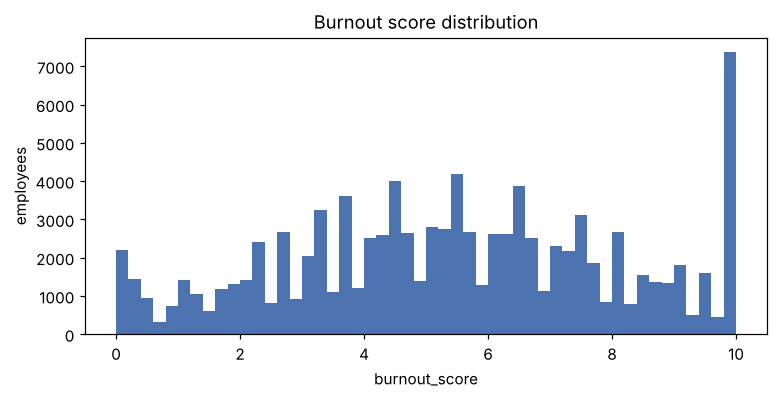

In [10]:
print(df[TARGET].describe().round(2))
print(f"\nskewness: {df[TARGET].skew():.3f}")
print(f"scores at exactly 0:  {(df[TARGET] == 0).mean():.1%}")
print(f"scores at exactly 10: {(df[TARGET] == 10).mean():.1%}")

plt.figure(figsize=(8, 3.5))
plt.hist(df[TARGET], bins=50, color="#4C72B0")
plt.xlabel("burnout_score")
plt.ylabel("employees")
plt.title("Burnout score distribution")
plt.show()

The score is between 0 and 10 and roughly symmetric, but some employees sit exactly at 0 or 10, so the extremes are capped.

In [11]:
df.groupby("burnout_level")[TARGET].agg(["min", "max", "count"]).sort_values("min")

,min,max,count
burnout_level,,,
Low,0.0,3.5,25807
Moderate,3.6,5.5,26255
High,5.6,7.0,19362
Severe,7.1,10.0,28576


`burnout_level` is not an independent column: each level is just a range of `burnout_score`.

### Correlations

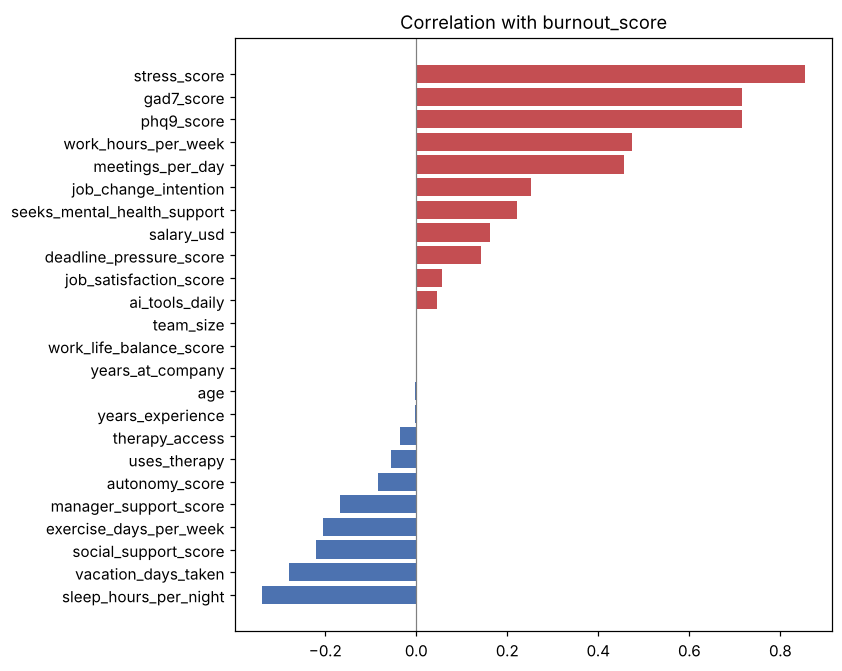

In [12]:
num_cols = df.select_dtypes("number").columns.drop(["employee_id", TARGET])
corr = df[num_cols].corrwith(df[TARGET]).sort_values()

plt.figure(figsize=(7, 7))
plt.barh(corr.index, corr.values, color=np.where(corr > 0, "#C44E52", "#4C72B0"))
plt.axvline(0, color="grey", lw=0.8)
plt.title("Correlation with burnout_score")
plt.show()

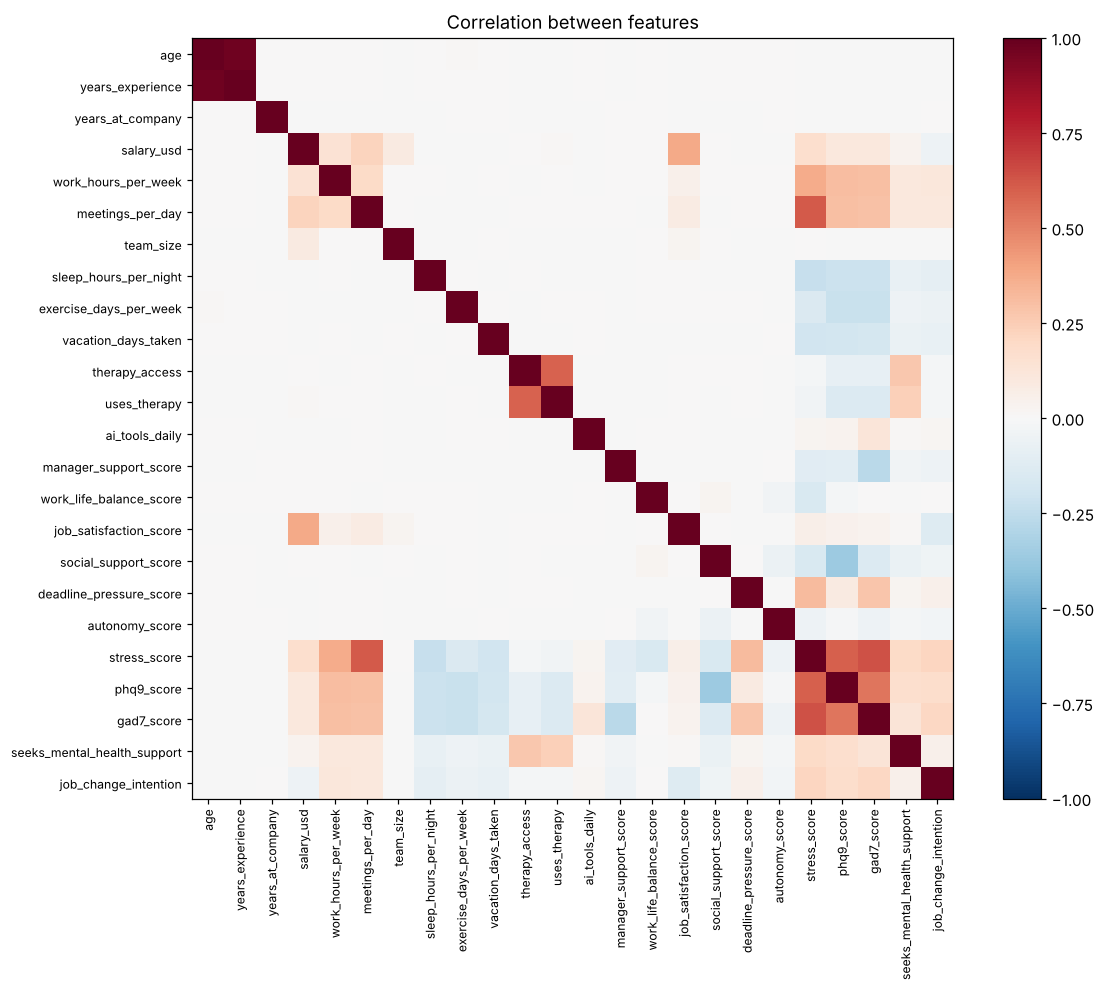

In [13]:
cm = df[num_cols].corr()
plt.figure(figsize=(11, 9))
plt.imshow(cm, cmap="RdBu_r", vmin=-1, vmax=1)
plt.xticks(range(len(cm)), cm.columns, rotation=90, fontsize=8)
plt.yticks(range(len(cm)), cm.columns, fontsize=8)
plt.colorbar()
plt.title("Correlation between features")
plt.tight_layout()
plt.show()

### Categorical features

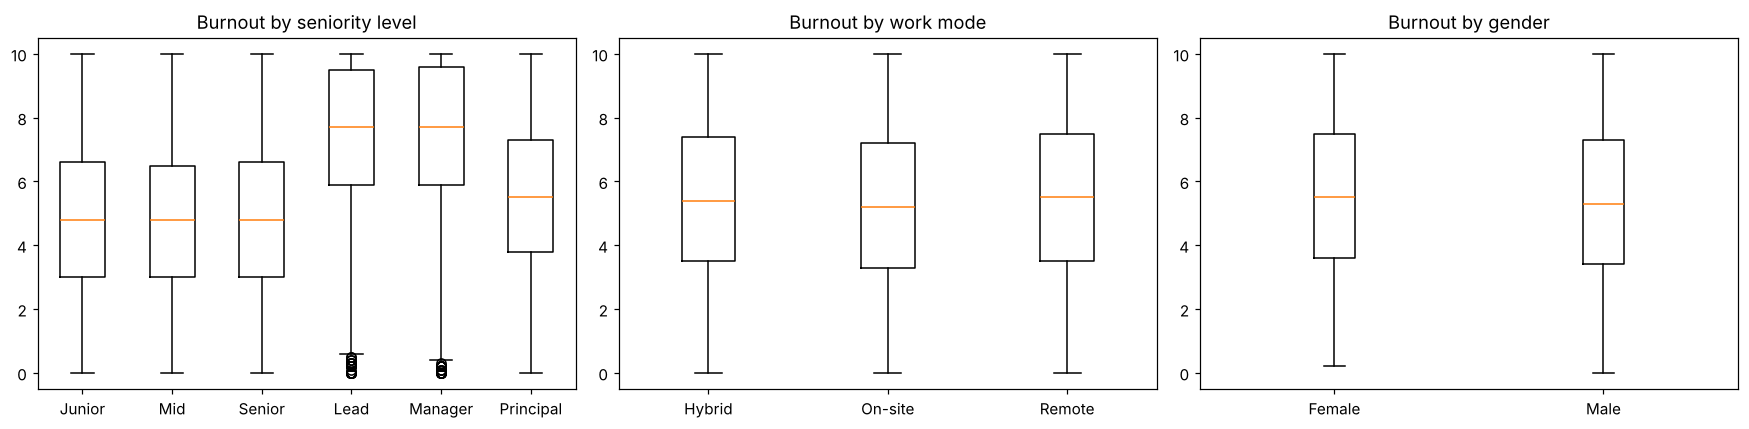

In [14]:
order = ["Junior", "Mid", "Senior", "Lead", "Manager", "Principal"]
modes = sorted(df.work_mode.unique())
genders = ["Female", "Male"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].boxplot([df.loc[df.seniority_level == l, TARGET] for l in order])
axes[0].set_xticks(range(1, len(order) + 1), order)
axes[0].set_title("Burnout by seniority level")
axes[1].boxplot([df.loc[df.work_mode == m, TARGET] for m in modes])
axes[1].set_xticks(range(1, len(modes) + 1), modes)
axes[1].set_title("Burnout by work mode")
axes[2].boxplot([df.loc[df.gender == g, TARGET] for g in genders])
axes[2].set_xticks(range(1, len(genders) + 1), genders)
axes[2].set_title("Burnout by gender")
plt.tight_layout()
plt.show()

In [15]:
features = ["seniority_level", "industry", "work_mode", "gender", "job_role", "company_size", "country"]
eta = {}
for c in features:
    g = df.groupby(c)[TARGET]
    eta[c] = (g.count() * (g.mean() - df[TARGET].mean()) ** 2).sum() / ((df[TARGET] - df[TARGET].mean()) ** 2).sum()
pd.Series(eta).sort_values(ascending=False).round(3).to_frame("share of variance explained (eta²)")

,share of variance explained (eta²)
seniority_level,0.166
industry,0.002
work_mode,0.001
gender,0.001
job_role,0.000
country,0.000
company_size,0.000


**What the EDA shows**
- `stress_score` has the strongest relationship with burnout, followed by work hours and meetings. Sleep and vacation days go the other way.
- `phq9_score` and `gad7_score` are also strongly correlated, but they are mental-health outcomes measured at the same time as burnout, not causes.
- Seniority is the only categorical feature that matters: Leads and Managers score clearly higher. Country, job role, industry, company size, work mode and gender explain almost nothing.
- `age` and `years_experience` are almost the same variable.

## 4. Preprocessing

### 4.1 Dropping leakage columns

| Dropped column(s) | Reason |
| --- | --- |
| employee_id | Just an ID |
| burnout_level | The target split into ranges (leakage) |
| phq9_score, phq9_category, gad7_score, gad7_category | Depression and anxiety scores measured at the same time as burnout |
| seeks_mental_health_support, job_change_intention | Results of burnout, not causes |

`stress_score` is kept as a predictor.

In [16]:
print("dropped:", DROP_COLS)
print("features left:", df.drop(columns=DROP_COLS + [TARGET]).shape[1])

dropped: ['employee_id', 'burnout_level', 'phq9_score', 'phq9_category', 'gad7_score', 'gad7_category', 'seeks_mental_health_support', 'job_change_intention']
features left: 27


### 4.2 Outliers (1.5 × IQR rule)

In [17]:
num = df.drop(columns=DROP_COLS + [TARGET]).select_dtypes("number")
outliers = {}
for c in num.columns:
    q1, q3 = num[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    n = ((num[c] < q1 - 1.5 * iqr) | (num[c] > q3 + 1.5 * iqr)).sum()
    if n:
        outliers[c] = n
pd.Series(outliers).sort_values(ascending=False).to_frame("outliers")

,outliers
uses_therapy,15185
years_at_company,4600
team_size,3437
meetings_per_day,653
sleep_hours_per_night,634
deadline_pressure_score,535
salary_usd,430
work_hours_per_week,353
vacation_days_taken,275
age,167


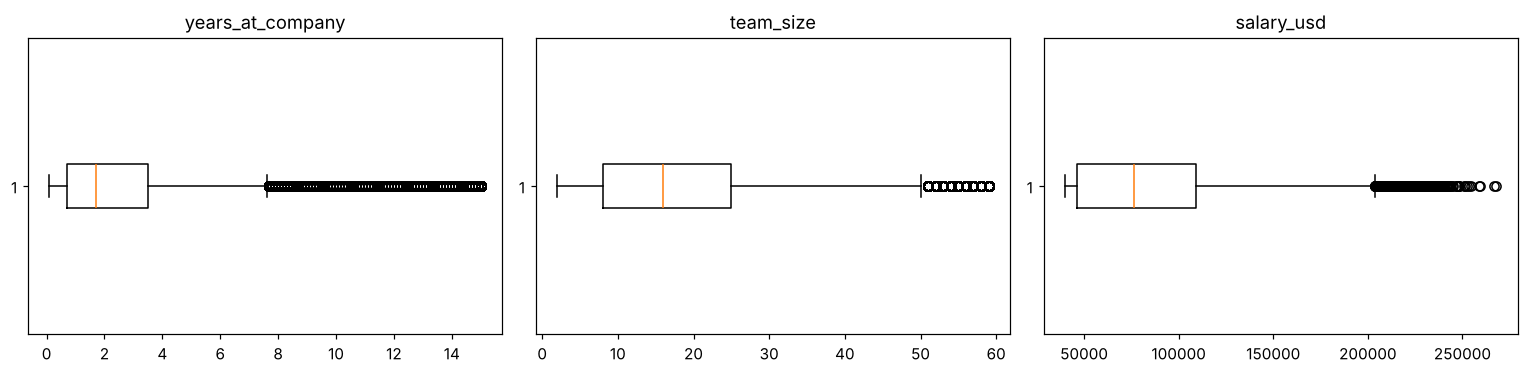

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, c in zip(axes, ["years_at_company", "team_size", "salary_usd"]):
    ax.boxplot(df[c], vert=False)
    ax.set_title(c)
plt.tight_layout()
plt.show()

In [19]:
# share of employees at the minimum salary, by country
at_min = df["salary_usd"] == df["salary_usd"].min()
print("minimum salary:", df["salary_usd"].min())
at_min.groupby(df["country"]).mean().sort_values(ascending=False).round(3).head(5)

minimum salary: 40000


country
India          0.774
Brazil         0.451
France         0.061
Singapore      0.047
Netherlands    0.033
Name: salary_usd, dtype: float64

These are long but realistic tails (long tenures, big teams, high salaries), not entry errors, so all rows are kept. Binary columns are flagged only because they are 0/1.

### 4.3 Logic rules

In [20]:
print("experience > age - 18:", (df.years_experience > df.age - 18).sum())
print("tenure > experience:  ", (df.years_at_company > df.years_experience).sum())

experience > age - 18: 120
tenure > experience:   18101


In [21]:
# rule 2 is applied after rule 1 has lowered some experience values, so it affects a few more rows
step1 = df.assign(years_experience=df["years_experience"].clip(upper=df["age"] - 18))
print("tenure > experience after rule 1:", (step1.years_at_company > step1.years_experience).sum())

tenure > experience after rule 1: 18103


In [22]:
def fix_logic(X):
    # experience can't exceed working-age years, and tenure can't exceed experience
    X = X.copy()
    if {"age", "years_experience"}.issubset(X.columns):
        X["years_experience"] = X["years_experience"].clip(upper=X["age"] - 18)
    if {"years_experience", "years_at_company"}.issubset(X.columns):
        X["years_at_company"] = X["years_at_company"].clip(upper=X["years_experience"])
    return X

In [23]:
fixed = fix_logic(df)
print("after fixing:")
print("experience > age - 18:", (fixed.years_experience > fixed.age - 18).sum())
print("tenure > experience:  ", (fixed.years_at_company > fixed.years_experience).sum())

after fixing:
experience > age - 18: 0
tenure > experience:   0


The values are corrected instead of removing rows. The fix runs inside the pipeline (4.5), so it is applied the same way to training data, test data and new employees from the website.

### 4.4 Train/test split

In [24]:
def load_and_split(path=DATA_PATH):
    df = load_data(path)
    X = df.drop(columns=DROP_COLS + [TARGET])
    y = df[TARGET]

    # no date column, so a random split is fine.
    # burnout_score is continuous, so we group it into 10 bins to stratify the split
    y_bins = pd.qcut(y, q=10, labels=False, duplicates="drop")
    return train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y_bins)

In [25]:
X_train, X_test, y_train, y_test = load_and_split()
print("train:", X_train.shape, " test:", X_test.shape)
print("train target mean/std:", round(y_train.mean(), 2), round(y_train.std(), 2))
print("test target mean/std: ", round(y_test.mean(), 2), round(y_test.std(), 2))

train: (80000, 27)  test: (20000, 27)
train target mean/std: 5.4 2.67
test target mean/std:  5.4 2.67


### 4.5 Preprocessing pipeline

Numeric columns: median imputation + scaling. Categorical columns: most-frequent imputation + one-hot encoding. The logic rules run first. Employees with no gender (for example from the website form) are given "Prefer not to say" as their own category, instead of the most common value (Male), so the model does not assume a gender.

In [26]:
def clean_gender(X):
    # missing gender gets its own category instead of the most common one (Male),
    # and gender values outside the form's options are treated the same way
    X = X.copy()
    if "gender" in X.columns:
        X["gender"] = X["gender"].replace(GENDER_RECODE).replace("", None).fillna("Prefer not to say")
    return X

In [27]:
def build_preprocessor(X):
    num_cols = X.select_dtypes("number").columns.tolist()
    cat_cols = X.select_dtypes(exclude="number").columns.tolist()

    numeric = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    categorical = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    columns = ColumnTransformer([
        ("num", numeric, num_cols),
        ("cat", categorical, cat_cols),
    ])

    # fix the logic rules and gender values first, then impute / scale / encode
    return Pipeline([
        ("fix", FunctionTransformer(fix_logic)),
        ("gender", FunctionTransformer(clean_gender)),
        ("columns", columns),
    ])

In [28]:
prep = build_preprocessor(X_train)
X_train_t = prep.fit_transform(X_train)
print("features before:", X_train.shape[1], " after preprocessing:", X_train_t.shape[1], "\n")
ct = prep.named_steps["columns"]
print("1. fix: logic rules (fix_logic)")
print("2. gender: missing or unknown gender -> Prefer not to say (clean_gender)")
for i, (name, pipe, cols) in enumerate(ct.transformers_[:2], start=3):
    steps = " -> ".join(type(step).__name__ for _, step in pipe.steps)
    print(f"{i}. {name} ({len(cols)} columns): {steps}")

features before: 27  after preprocessing: 69 

1. fix: logic rules (fix_logic)
2. gender: missing or unknown gender -> Prefer not to say (clean_gender)
3. num (20 columns): SimpleImputer -> StandardScaler
4. cat (7 columns): SimpleImputer -> OneHotEncoder


Each model notebook puts this pipeline inside its own Pipeline, so it is re-fitted on the training folds only during cross-validation.